In [1]:
from MultiAgent_DQ import *
import numpy as np
import pandas as pd  
import itertools
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import pandas as pd
import sys
sys.path.append('../')
import tqdm
from utils import *


In [2]:
import pandas as pd
from pathlib import Path

# Split df_fixed into two blocks (first 225 rows and next 225 rows)
# and save them as separate CSV files for quick inspection.
base_dir = Path("..")
df_fixed_path = base_dir / "results" / "results_vect_paramsfixed_time2000.csv"

df_fixed_local = pd.read_csv(df_fixed_path)

df_2000_0702 = df_fixed_local.iloc[:225].copy()
df_2000_0805 = df_fixed_local.iloc[225:450].copy()

out_0702 = base_dir / "results" / "2000_0702.csv"
out_0805 = base_dir / "results" / "2000_0805.csv"

df_2000_0702.to_csv(out_0702, index=False)
df_2000_0805.to_csv(out_0805, index=False)

print(f"Saved: {out_0702} ({len(df_2000_0702)} rows)")
print(f"Saved: {out_0805} ({len(df_2000_0805)} rows)")

# Quick comparison to highlight differences
compare_cols = [c for c in ["P_AD", "P_GT"] if c in df_fixed_local.columns]
summary_0702 = df_2000_0702[compare_cols].describe(include="all").T
summary_0805 = df_2000_0805[compare_cols].describe(include="all").T

print("\nUnique values by split (settings columns):")
for col in ["alpha", "lambda", "e", "delta", "M"]:
    if col in df_fixed_local.columns:
        print(f"{col}:\n  0702 -> {sorted(df_2000_0702[col].dropna().unique().tolist())}\n  0805 -> {sorted(df_2000_0805[col].dropna().unique().tolist())}")

summary_0702, summary_0805

Saved: ../results/2000_0702.csv (225 rows)
Saved: ../results/2000_0805.csv (225 rows)

Unique values by split (settings columns):
alpha:
  0702 -> [0.01, 0.25, 0.5, 0.75, 1.0]
  0805 -> [0.01, 0.25, 0.5, 0.75, 1.0]
lambda:
  0702 -> [0.01, 0.1, 0.2, 0.3, 0.4]
  0805 -> [0.01, 0.1, 0.2, 0.3, 0.4]
e:
  0702 -> [0.05, 0.1, 0.2]
  0805 -> [0.05, 0.1, 0.2]
delta:
  0702 -> [0.5, 0.75, 0.95]
  0805 -> [0.5, 0.75, 0.95]
M:
  0702 -> [2000]
  0805 -> [2000]


(      count      mean       std     min     25%     50%     75%     max
 P_AD  225.0  0.640711  0.155046  0.3675  0.4950  0.6535  0.7555  0.9225
 P_GT  225.0  0.359289  0.155046  0.0775  0.2445  0.3465  0.5050  0.6325,
       count      mean       std     min     25%    50%     75%     max
 P_AD  225.0  0.727869  0.142128  0.4195  0.6410  0.743  0.8105  1.0000
 P_GT  225.0  0.272131  0.142128  0.0000  0.1895  0.257  0.3590  0.5805)

## reading results from simulations

In [ ]:

df_fixed = pd.read_csv("../results/results_vect_paramsfixed_time2000.csv") 


In [3]:
df_fixed

,M,alpha,lambda,e,delta,random_uniform,P_AD,P_GT,nonconv,time_max,time_min,time_mean
0,2000,0.01,0.01,0.05,0.50,False,0.7345,0.2655,0,0.380239,0.125445,0.263646
1,2000,0.01,0.01,0.05,0.75,False,0.4750,0.5250,0,0.473864,0.150943,0.321422
2,2000,0.01,0.01,0.05,0.95,False,0.3725,0.6275,0,0.754080,0.204645,0.535738
3,2000,0.01,0.01,0.10,0.75,False,0.5100,0.4900,0,0.474289,0.149031,0.248350
4,2000,0.01,0.01,0.10,0.50,False,0.7890,0.2110,0,0.385735,0.129770,0.316255
...,...,...,...,...,...,...,...,...,...,...,...,...
445,2000,1.00,0.40,0.20,0.50,False,1.0000,0.0000,0,0.007757,0.002037,0.004691
446,2000,1.00,0.40,0.05,0.95,False,0.7620,0.2380,0,0.119130,0.024802,0.047384
447,2000,1.00,0.40,0.20,0.75,False,0.7450,0.2550,0,0.025932,0.004547,0.010060
448,2000,1.00,0.40,0.10,0.95,False,0.7620,0.2380,0,0.109948,0.024295,0.047810


In [ ]:
df = pd.read_csv("../results/results_from_vectorized_script_raw.csv")
df_new = pd.read_csv('../results/results_vect_ADGT.csv')
df_08_05 = pd.read_csv('../results/results_vect_ADGT_0.8_0.5_more_e.csv')
df_07_02 = pd.read_csv('../results/results_vect_ADGT_0.7_0.2_more_e.csv')
df_08_05_uniform = pd.read_csv('../results/results_vect_uniform_0.8_0.5_more_e.csv')
df_07_02_uniform = pd.read_csv('../results/results_vect_uniform_0.7_0.2_more_e.csv')
df_ACGT = pd.read_csv('../results/results_vect_ACGT_0702.csv')


In [ ]:
df_fixed


In [ ]:
#excluding lambda > 0.8
df_fixed = df_fixed[df_fixed['lambda']<=0.8]

In [ ]:
def round_columns(df, columns, decimals):
    for column in columns:
        df[column] = df[column].round(decimals)
    return df

def round_to_quarters(df, columns, decimals):
    for column in columns:
        df[column] = (df[column]/ 0.25).round(decimals)* 0.25
    return df

# Columns to round
columns_to_round = ['delta', 'e', 'lambda', 'alpha']

# Apply the function to df
# Apply the function to df_fixed
df_fixed = round_columns(df_fixed, columns_to_round, 2)
df = round_columns(df, columns_to_round, 2)
df_new = round_columns(df_new, columns_to_round, 2)
df_08_05 = round_columns(df_08_05, columns_to_round, 2)
df_07_02 = round_columns(df_07_02, columns_to_round, 2)
df_08_05_uniform= round_columns(df_08_05_uniform, columns_to_round, 2)
df_07_02_uniform= round_columns(df_07_02_uniform, columns_to_round, 2)
df_ACGT= round_columns(df_ACGT, columns_to_round, 2)

df_fixed['M'] = df_fixed['M'].round(0)
df_new['M'] = df_new['M'].round(0)


In [ ]:
columns = ['delta', 'e', 'lambda', 'alpha']

# Generate all pairwise combinations of the columns
pair_combinations = list(itertools.combinations(columns, 2))

# Display the pair combinations
print(pair_combinations)

In [ ]:
heatmap_3d_voxels(df_08_05, 'delta', 'lambda', 'alpha', value='P_AD')
heatmap_3d_voxels(df_07_02, 'delta', 'lambda', 'alpha', value='P_AD')


In [ ]:
interactive_3d_voxel(df, 'delta', 'lambda', 'alpha', value='P_AD', html= False)

In [ ]:
heatmap_mean(df, 'delta', 'e', 'P_AD')

In [ ]:
lambdas = np.sort(df_fixed['lambda'].unique())
lambdas

In [ ]:
def filter_for_plot(df, na = 5, nl = 8):
    alphas = np.sort(df['alpha'].unique())
    selected = alphas[np.linspace(0, len(alphas) - 1, na).astype(int)]
    lambdas = np.sort(df['lambda'].unique())
    selected_l = lambdas[np.linspace(0, len(lambdas) - 1, nl).astype(int)]
    stric_s = selected_l[:-3]
    df_filtered = df[df['alpha'].isin(selected)]
    df_filtered = df_filtered[df_filtered['lambda'].isin(stric_s)]
    return df_filtered

In [ ]:
df_filtered = filter_for_plot(df_07_02, na = 5, nl = 8)
print('alpha values:',df_filtered['alpha'].unique())
print('lambda values:', df_filtered['lambda'].unique())


In [ ]:
df_filtered.M.value_counts()

In [ ]:
df_fixed

## Uniform Initialization

In [3]:
from basin import *

In [4]:
e, delta = 0.2,0.5
t, r, p, s = 1, 0.7, 0.2, 0
get_aggregate_bounds(t=t, r=r, p=p, s=s, epsilon=e, d=delta, P_AD = True)

(np.float64(0.5565476190476188), np.float64(0.8690476190476188))

In [5]:
df_2000_0702

,M,alpha,lambda,e,delta,random_uniform,P_AD,P_GT,nonconv,time_max,time_min,time_mean
0,2000,0.01,0.01,0.05,0.50,False,0.7345,0.2655,0,0.380239,0.125445,0.263646
1,2000,0.01,0.01,0.05,0.75,False,0.4750,0.5250,0,0.473864,0.150943,0.321422
2,2000,0.01,0.01,0.05,0.95,False,0.3725,0.6275,0,0.754080,0.204645,0.535738
3,2000,0.01,0.01,0.10,0.75,False,0.5100,0.4900,0,0.474289,0.149031,0.248350
4,2000,0.01,0.01,0.10,0.50,False,0.7890,0.2110,0,0.385735,0.129770,0.316255
...,...,...,...,...,...,...,...,...,...,...,...,...
220,2000,1.00,0.40,0.20,0.50,False,0.7480,0.2520,0,0.012554,0.002037,0.004552
221,2000,1.00,0.40,0.20,0.75,False,0.7280,0.2720,0,0.046787,0.004341,0.009795
222,2000,1.00,0.40,0.05,0.95,False,0.7495,0.2505,0,0.119241,0.023286,0.045942
223,2000,1.00,0.40,0.10,0.95,False,0.7595,0.2405,0,0.141725,0.024314,0.046118


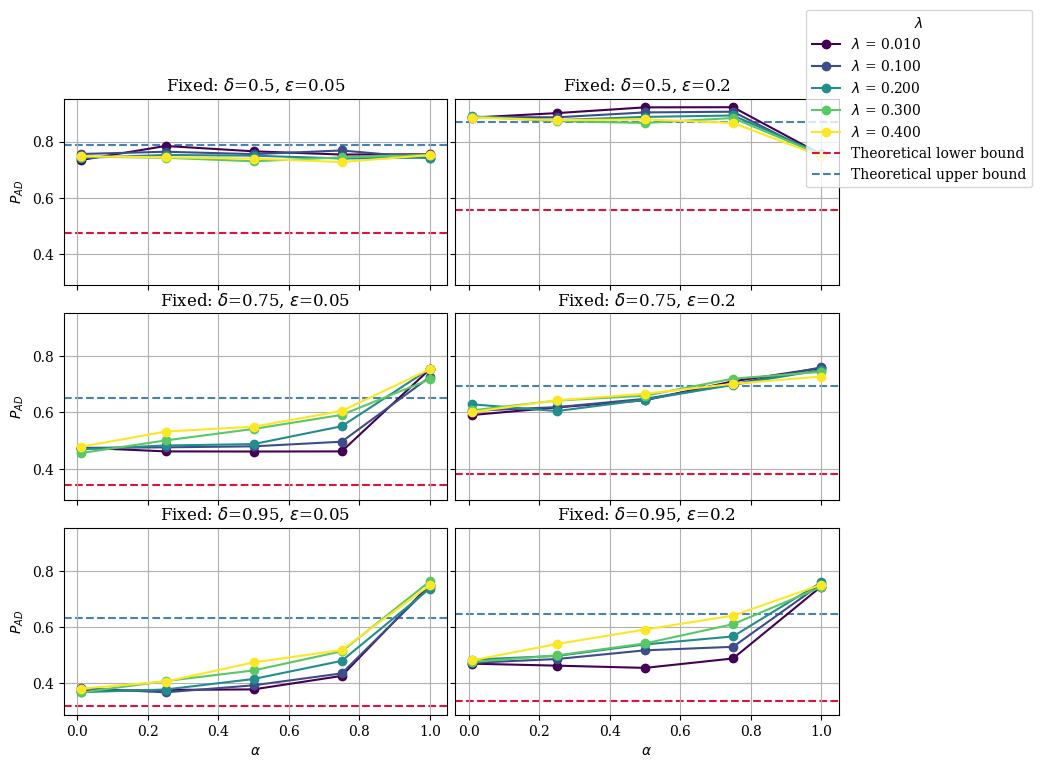

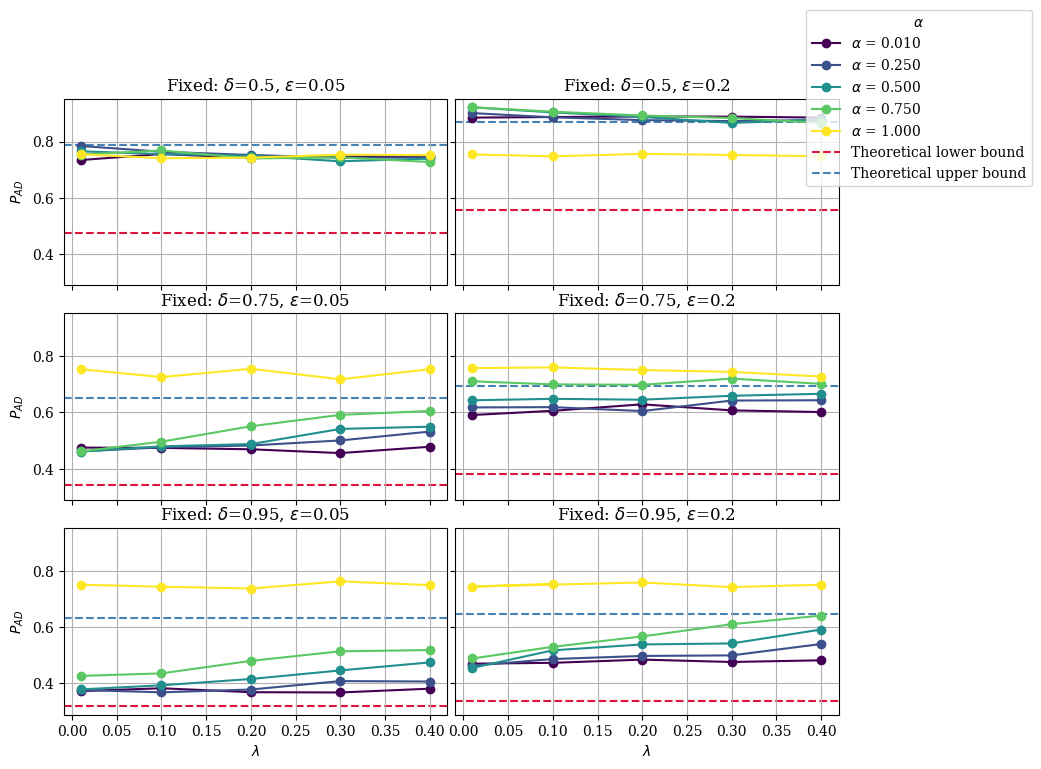

In [6]:
#df_07_02_uniform_filtered = filter_for_plot(df_07_02_uniform, na = 5, nl = 8)
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.2},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.2},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.2},
]

y = 'P_AD'

t, r, p, s = 1, 0.7, 0.2, 0
from MultiAgent.basin import get_aggregate_bounds
theoretical_bounds = [get_aggregate_bounds(t=t, r=r, p=p, s=s, epsilon=ps['e'], d=ps['delta']) for ps in param_sets]


plot_multiple_panels(df_2000_0702, param_sets, x_var="alpha", varying_var="lambda", y_var=y, m=2000, use_same_scale=True, cmap = 'viridis', theoretical_bounds=theoretical_bounds)
plot_multiple_panels(df_2000_0702, param_sets, x_var="lambda", varying_var="alpha", y_var=y, m=2000, use_same_scale=True, cmap = 'viridis', theoretical_bounds=theoretical_bounds)

In [7]:
e, delta = 0.05,0.95
t, r, p, s = 1, 0.8, 0.5, 0
get_aggregate_bounds(t=t, r=r, p=p, s=s, epsilon=e, d=delta, P_AD = True)

(np.float64(0.3371250000000001), np.float64(0.6496250000000001))

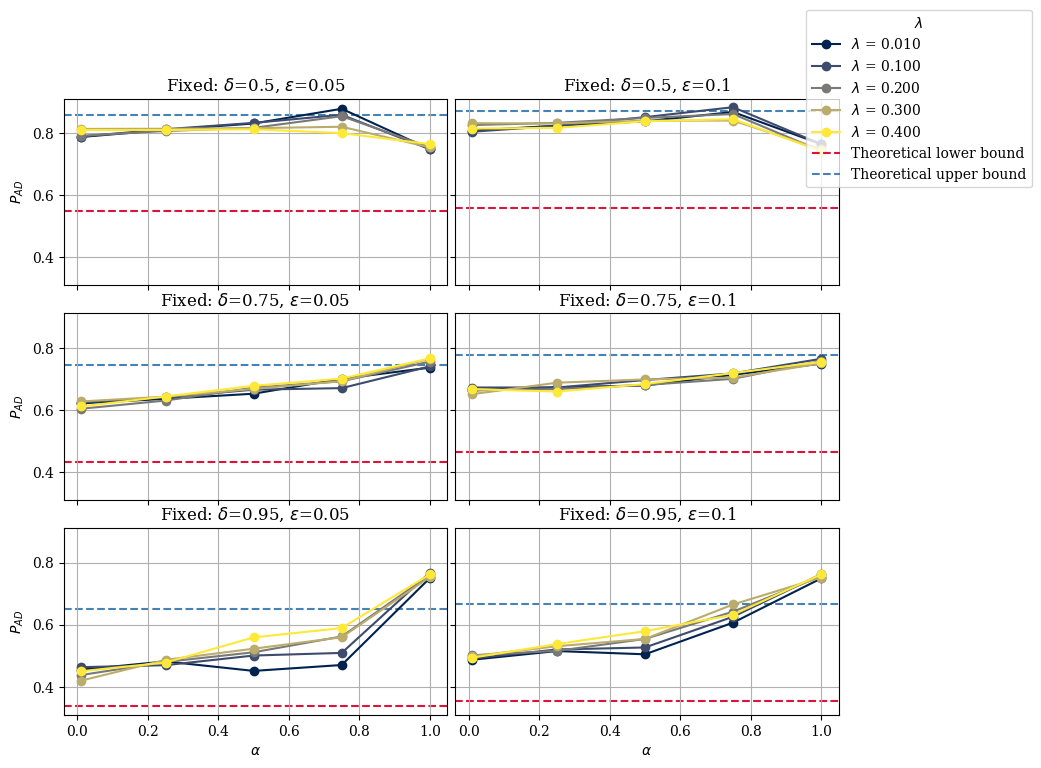

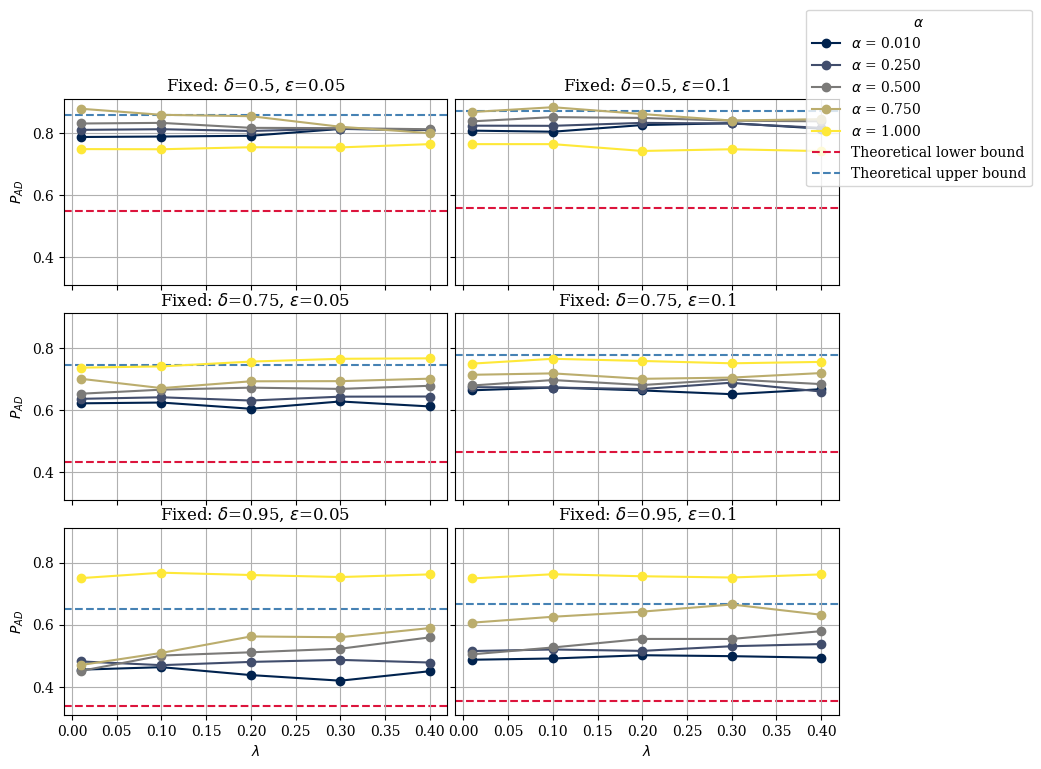

In [8]:
#df_08_05_uniform_filtered = filter_for_plot(df_08_05_uniform, na = 5, nl = 8)
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.1},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.1},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.1},
]


y = 'P_AD'

t, r, p, s = 1, 0.8, 0.5, 0
from MultiAgent.basin import get_aggregate_bounds
theoretical_bounds = [get_aggregate_bounds(t=t, r=r, p=p, s=s, epsilon=ps['e'], d=ps['delta']) for ps in param_sets]


plot_multiple_panels(df_2000_0805, param_sets, x_var="alpha", varying_var="lambda", y_var=y, m=2000, use_same_scale=True, cmap = 'cividis', theoretical_bounds=theoretical_bounds)
plot_multiple_panels(df_2000_0805, param_sets, x_var="lambda", varying_var="alpha", y_var=y, m=2000, use_same_scale=True, cmap = 'cividis', theoretical_bounds=theoretical_bounds)

## ADGT plots

In [ ]:
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.2},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.2},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.2},
]

m=100
y = 'P_AD'

t, r, p, s = 1, 0.7, 0.2, 0
from MultiAgent.basin import theoretical_P_AD_from_ADGT

theoretical_per_panel = [theoretical_P_AD_from_ADGT(t=t, r=r, p=p, s=s, delta=ps['delta'], e=ps['e']) for ps in param_sets]
theoretical_per_panel_c_s = [theoretical_P_AD_from_ADGT(t=t, r=r, p=p, s=s, delta=ps['delta'], e=ps['e']) for ps in param_sets]
#TODO:color-blind cmap.
plot_multiple_panels(df_filtered, param_sets, x_var="alpha", varying_var="lambda", y_var=y, m=100, use_same_scale=True, cmap = 'viridis', theoretical_basin_AD=theoretical_per_panel_c_s)
plot_multiple_panels(df_filtered, param_sets, x_var="lambda", varying_var="alpha", y_var=y, m=100, use_same_scale=True, cmap = 'viridis', theoretical_basin_AD=theoretical_per_panel_c_s)

In [ ]:
df_filtered_s = filter_for_plot(df_08_05, na = 5, nl = 8)

In [ ]:
df_filtered_s.e.unique()

In [ ]:
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.1},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.1},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.1},
]

m=100
y = 'P_AD'
from MultiAgent.basin import theoretical_P_AD_from_ADGT
theoretical_per_panel_c = [theoretical_P_AD_from_ADGT(t=1, r=0.8, p=0.5, s=0, delta=ps['delta'], e=ps['e']) for ps in param_sets]

plot_multiple_panels(df_filtered_s, param_sets, x_var="alpha", varying_var="lambda", y_var=y, m=m, use_same_scale=True, cmap = 'cividis', theoretical_basin_AD=theoretical_per_panel_c)
plot_multiple_panels(df_filtered_s, param_sets, x_var="lambda", varying_var="alpha", y_var=y, m=m, use_same_scale=True, cmap = 'cividis', theoretical_basin_AD=theoretical_per_panel_c)

## ACGT Plots

In [ ]:
df_filtered = filter_for_plot(df_ACGT, na = 5, nl = 8)

In [ ]:
df_ACGT['P_GT'].mean()

In [ ]:
df_ACGT['P_AD'].mean()

In [ ]:
def theoretical_P_AD_from_ACGT(t=1, r=0.7, p=0.2, s=0, epsilon=0.1, d=0.6,
                                state_idx=0, delta=None, e=None):
    """
    Theoretical P(AD) from the (AC, GT) initialization.
    From Proposition (general basin), the symmetric bifurcation case:
    P(GT,GT | GT,AC) = 0.5 * (1 + pi_GTGT)
    Therefore:
    P(AD,AD | GT,AC) = 1 - P(GT,GT | GT,AC) = 1 - 0.5 * (1 + pi_GTGT)
                     = 0.5 * (1 - pi_GTGT)
    """
    if delta is not None:
        d = delta
    if e is not None:
        epsilon = e

    Q_AD = QvaluesADvsAD(t, r, p, s, epsilon, d)[state_idx]
    Q_GT = QvaluesGTvsGT(t, r, p, s, epsilon, d)[state_idx]

    abs_dx = abs(Q_AD[0] - Q_AD[1])
    abs_dy = abs(Q_GT[0] - Q_GT[1])

    pi_small = 0.5 * min(abs_dx, abs_dy) / max(abs_dx, abs_dy) if max(abs_dx, abs_dy) > 0 else 0.5
    pi_GTGT = (1.0 - pi_small) if abs_dx < abs_dy else (pi_small if abs_dx > abs_dy else 0.5)

    P_AD = 0.5 * (1 - pi_GTGT)
    return float(P_AD)

In [ ]:
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.2},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.2},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.2},
]

m=100
y = 'P_AD'

t, r, p, s = 1, 0.7, 0.2, 0
theoretical_per_panel_acgt = [theoretical_P_AD_from_ACGT(t=1, r=0.7, p=0.2, s=0, delta=ps['delta'], e=ps['e']) for ps in param_sets]
plot_multiple_panels(df_filtered, param_sets, x_var="alpha", varying_var="lambda", y_var=y, m=100, use_same_scale=True, cmap = 'viridis', theoretical_basin_AD=theoretical_per_panel_acgt)
plot_multiple_panels(df_filtered, param_sets, x_var="lambda", varying_var="alpha", y_var=y, m=100, use_same_scale=True, cmap = 'viridis', theoretical_basin_AD=theoretical_per_panel_acgt)